In [1]:

!pip install pandas numpy matplotlib seaborn scikit-learn statsmodels

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score

import statsmodels.api as sm

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

columns = [
    'age', 'workclass', 'fnlwgt', 'education',
    'education-num', 'marital-status', 'occupation',
    'relationship', 'race', 'sex', 'capital-gain',
    'capital-loss', 'hours-per-week',
    'native-country', 'income'
]

train_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

test_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test"

train = pd.read_csv(
    train_url,
    names=columns,
    skipinitialspace=True
)

test = pd.read_csv(
    test_url,
    names=columns,
    skiprows=1,
    skipinitialspace=True
)

df = pd.concat([train, test], ignore_index=True)

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())


Dataset downloaded successfully!
Dataset shape: (48842, 15)
   age         workclass  fnlwgt  education  education-num  \
0   39         State-gov   77516  Bachelors             13   
1   50  Self-emp-not-inc   83311  Bachelors             13   
2   38           Private  215646    HS-grad              9   
3   53           Private  234721       11th              7   
4   28           Private  338409  Bachelors             13   

       marital-status         occupation   relationship   race     sex  \
0       Never-married       Adm-clerical  Not-in-family  White    Male   
1  Married-civ-spouse    Exec-managerial        Husband  White    Male   
2            Divorced  Handlers-cleaners  Not-in-family  White    Male   
3  Married-civ-spouse  Handlers-cleaners        Husband  Black    Male   
4  Married-civ-spouse     Prof-specialty           Wife  Black  Female   

   capital-gain  capital-loss  hours-per-week native-country income  
0          2174             0              40  Unite

In [3]:

# Step 3: Clean the dataset

# Remove extra spaces
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# Replace ? with missing values
df.replace('?', np.nan, inplace=True)

# Remove duplicate rows
df.drop_duplicates(inplace=True)

# Create income target
df['income'] = df['income'].str.rstrip('.')

df['target'] = (df['income'] == '>50K').astype(int)

# Check missing values
print("Missing values:")
print(df.isnull().sum())

print("\nIncome distribution:")
print(df['target'].value_counts())

print("\nDataset shape:", df.shape)


Missing values:
age                  0
workclass         2799
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     856
income               0
target               0
dtype: int64

Income distribution:
target
0    37128
1    11685
Name: count, dtype: int64

Dataset shape: (48813, 16)


In [4]:

# Fill missing categorical values with their mode

categorical_columns = [
    'workclass',
    'occupation',
    'native-country'
]

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nDataset shape:", df.shape)


Missing values after cleaning:
age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
target            0
dtype: int64

Dataset shape: (48813, 16)


In [5]:

# Separate input features and target

X = df.drop(columns=['income', 'target'])
y = df['target']

# Convert categorical columns into numerical columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Data converted successfully!")
print("Total features:", X.shape[1])
print(X.head())


Data converted successfully!
Total features: 97
   age  fnlwgt  education-num  capital-gain  capital-loss  hours-per-week  \
0   39   77516             13          2174             0              40   
1   50   83311             13             0             0              13   
2   38  215646              9             0             0              40   
3   53  234721              7             0             0              40   
4   28  338409             13             0             0              40   

   workclass_Local-gov  workclass_Never-worked  workclass_Private  \
0                    0                       0                  0   
1                    0                       0                  0   
2                    0                       0                  1   
3                    0                       0                  1   
4                    0                       0                  1   

   workclass_Self-emp-inc  ...  native-country_Portugal  \
0              

In [6]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=179,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 34169
Testing records: 14644


In [7]:

# Model A: Linear Regression using OLS

X_train_ols = sm.add_constant(X_train)
X_test_ols = sm.add_constant(X_test)

model_a = sm.OLS(y_train, X_train_ols).fit()

pred_a = model_a.predict(X_test_ols)

print("Linear Regression Model Created Successfully!")

print("\nModel Summary:")
print(model_a.summary())


Linear Regression Model Created Successfully!

Model Summary:
                            OLS Regression Results                            
Dep. Variable:                 target   R-squared:                       0.363
Model:                            OLS   Adj. R-squared:                  0.361
Method:                 Least Squares   F-statistic:                     201.9
Date:                Sat, 21 Nov 2026   Prob (F-statistic):               0.00
Time:                        18:52:21   Log-Likelihood:                -11688.
No. Observations:               34169   AIC:                         2.357e+04
Df Residuals:                   34072   BIC:                         2.439e+04
Df Model:                          96                                         
Covariance Type:            nonrobust                                         
                                                coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------

/tmp/ipykernel_1049/232058145.py:6: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model_a = sm.OLS(y_train, X_train_ols).fit()


In [8]:

# Model B: Logistic Regression

model_b = LogisticRegression(max_iter=1000)

model_b.fit(X_train, y_train)

# Predict probabilities
pred_b = model_b.predict_proba(X_test)[:, 1]

# Predict income classes
pred_b_class = model_b.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, pred_b_class)

print("Logistic Regression Model Created Successfully!")
print("Model Accuracy:", round(accuracy * 100, 2), "%")



Logistic Regression Model Created Successfully!
Model Accuracy: 84.78 %


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [9]:

# Compare Linear and Logistic Regression

threshold_a = np.median(pred_a)

class_a = (pred_a >= threshold_a).astype(int)
class_b = (pred_b >= 0.5).astype(int)

cm = confusion_matrix(class_a, class_b)

mismatch = np.sum(class_a != class_b)

print("Linear Regression Median:", threshold_a)

print("\nConfusion Matrix:")
print(cm)

print("\nMismatched Cases:", mismatch)

print("Mismatch Percentage:",
      round((mismatch / len(class_a)) * 100, 2), "%")


Linear Regression Median: 0.22278341853756245

Confusion Matrix:
[[7291   31]
 [4572 2750]]

Mismatched Cases: 4603
Mismatch Percentage: 31.43 %


In [10]:

# Fix Logistic Regression using feature scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model_b = LogisticRegression(max_iter=5000)

model_b.fit(X_train_scaled, y_train)

pred_b = model_b.predict_proba(X_test_scaled)[:, 1]

pred_b_class = (pred_b >= 0.5).astype(int)

accuracy = accuracy_score(y_test, pred_b_class)

print("Model trained successfully!")
print("New Accuracy:", round(accuracy * 100, 2), "%")



Model trained successfully!
New Accuracy: 85.52 %


In [11]:

threshold_a = np.median(pred_a)

class_a = (pred_a >= threshold_a).astype(int)
class_b = (pred_b >= 0.5).astype(int)

cm = confusion_matrix(class_a, class_b)

mismatch = np.sum(class_a != class_b)

print("Linear Regression Median:", threshold_a)
print("\nConfusion Matrix:\n", cm)
print("\nMismatched Cases:", mismatch)
print("Mismatch Percentage:",
      round(mismatch / len(class_a) * 100, 2), "%")


Linear Regression Median: 0.22278341853756245

Confusion Matrix:
 [[7308   14]
 [4488 2834]]

Mismatched Cases: 4502
Mismatch Percentage: 30.74 %


In [12]:

# Part 2.1: Simpson's Paradox Hunt

features = [
    'age',
    'education-num',
    'hours-per-week',
    'capital-gain'
]

def run_group_model(data, group_name):
    X_group = sm.add_constant(data[features])
    y_group = data['target']

    model = sm.Logit(y_group, X_group).fit(
        disp=False,
        maxiter=200
    )

    print("\n", group_name)
    print("Age coefficient:", model.params['age'])
    print("Age p-value:", model.pvalues['age'])
    print("Age confidence interval:")
    print(model.conf_int().loc['age'])

    return model

full_model = run_group_model(df, "Full Dataset")

male_data = df[df['sex'] == 'Male']
female_data = df[df['sex'] == 'Female']

male_model = run_group_model(male_data, "Male Group")
female_model = run_group_model(female_data, "Female Group")



 Full Dataset
Age coefficient: 0.043089447414417954
Age p-value: 0.0
Age confidence interval:
0    0.041166
1    0.045013
Name: age, dtype: float64

 Male Group
Age coefficient: 0.045865784186605356
Age p-value: 0.0
Age confidence interval:
0    0.043603
1    0.048128
Name: age, dtype: float64

 Female Group
Age coefficient: 0.029611803523430427
Age p-value: 2.918133140030171e-45
Age confidence interval:
0    0.025501
1    0.033723
Name: age, dtype: float64


In [14]:

# Part 2.2: Omitted Variable Bias

# Full model
full_features = [
    'age',
    'education-num',
    'hours-per-week',
    'capital-gain',
    'capital-loss'
]

X_full = sm.add_constant(df[full_features])
full_ovb = sm.Logit(df['target'], X_full).fit(disp=False)

# Reduced model: remove education-num
reduced_features = [
    'age',
    'hours-per-week',
    'capital-gain',
    'capital-loss'
]

# Part 2.3: Adversarial Subset

results = X_test.copy()

results['actual'] = y_test
results['probability'] = pred_b

# Find confident but incorrect predictions
wrong = results[
    ((results['probability'] >= 0.75) &
     (results['actual'] == 0)) |
    ((results['probability'] <= 0.25) &
     (results['actual'] == 1))
]

# Select up to 50 cases
sample = wrong.sample(
    n=min(50, len(wrong)),
    random_state=179
)

print("Total high-confidence wrong predictions:", len(wrong))

print("\nSelected sample:", len(sample))

print("\nGender distribution:")
print(sample['sex_Male'].value_counts())

print("\nAge statistics:")
print(sample['age'].describe())

print("\nEducation distribution:")
print(sample.filter(like='education_').sum().sort_values(ascending=False).head(10))

X_reduced = sm.add_constant(df[reduced_features])
reduced_ovb = sm.Logit(df['target'], X_reduced).fit(disp=False)

# Compare coefficients
comparison = pd.DataFrame({
    'Full Model': full_ovb.params[reduced_features],
    'Reduced Model': reduced_ovb.params[reduced_features]
})

comparison['Percentage Change'] = (
    abs(comparison['Reduced Model'] - comparison['Full Model'])
    / abs(comparison['Full Model'])
) * 100

print(comparison.round(4))


Total high-confidence wrong predictions: 711

Selected sample: 50

Gender distribution:
sex_Male
1    42
0     8
Name: count, dtype: int64

Age statistics:
count    50.000000
mean     40.940000
std      11.088531
min      24.000000
25%      31.250000
50%      39.500000
75%      49.250000
max      63.000000
Name: age, dtype: float64

Education distribution:
education_HS-grad         14
education_Bachelors       12
education_Some-college     9
education_Assoc-voc        3
education_Prof-school      2
education_Masters          2
education_11th             1
education_5th-6th          1
education_12th             1
education_7th-8th          1
dtype: int64
                Full Model  Reduced Model  Percentage Change
age                 0.0422         0.0380             9.9412
hours-per-week      0.0401         0.0435             8.5204
capital-gain        0.0003         0.0003             2.9619
capital-loss        0.0007         0.0008            11.9008


In [15]:

# Part 2.4: Fairness Trade-Off Analysis

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

thresholds = np.arange(0.05, 1.00, 0.10)

# Identify gender groups
gender = X_test['sex_Male'].to_numpy()
actual = np.asarray(y_test)
probabilities = np.asarray(pred_b)

fairness_results = []

for threshold in thresholds:

    predicted = (probabilities >= threshold).astype(int)

    group_metrics = {}

    for group, name in [(1, 'Male'), (0, 'Female')]:
        mask = gender == group

        yt = actual[mask]
        yp = predicted[mask]

        tn, fp, fn, tp = confusion_matrix(
            yt, yp, labels=[0, 1]
        ).ravel()

        dp = np.mean(yp == 1)
        tpr = tp / (tp + fn) if (tp + fn) else np.nan
        fpr = fp / (fp + tn) if (fp + tn) else np.nan
        pp = tp / (tp + fp) if (tp + fp) else np.nan

        group_metrics[name] = {
            'DP': dp, 'TPR': tpr,
            'FPR': fpr, 'PP': pp
        }

    m = group_metrics['Male']
    f = group_metrics['Female']

    def ratio(a, b):
        if pd.isna(a) or pd.isna(b) or max(a, b) == 0:
            return np.nan
        return min(a, b) / max(a, b)

    dp_ratio = ratio(m['DP'], f['DP'])
    tpr_ratio = ratio(m['TPR'], f['TPR'])
    fpr_ratio = ratio(m['FPR'], f['FPR'])
    pp_ratio = ratio(m['PP'], f['PP'])

    fairness_results.append({
        'Threshold': round(threshold, 2),
        'DP': dp_ratio,
        'TPR Ratio': tpr_ratio,
        'FPR Ratio': fpr_ratio,
        'EO': min(tpr_ratio, fpr_ratio)
             if not (pd.isna(tpr_ratio) or pd.isna(fpr_ratio))
             else np.nan,
        'PP': pp_ratio
    })

fairness_df = pd.DataFrame(fairness_results)

print("FAIRNESS RESULTS")
print(fairness_df.round(4).to_string(index=False))


FAIRNESS RESULTS
 Threshold     DP  TPR Ratio  FPR Ratio     EO     PP
      0.05 0.4767     0.9569     0.4469 0.4469 0.7164
      0.15 0.3221     0.8683     0.2606 0.2606 0.9620
      0.25 0.2944     0.8354     0.2255 0.2255 0.9875
      0.35 0.3029     0.8390     0.2412 0.2412 0.9884
      0.45 0.2926     0.8053     0.2385 0.2385 0.9820
      0.55 0.2740     0.7742     0.2080 0.2080 0.9918
      0.65 0.2607     0.7321     0.2013 0.2013 0.9980
      0.75 0.2479     0.6881     0.2082 0.2082 0.9906
      0.85 0.2418     0.6699     0.2240 0.2240 0.9886
      0.95 0.2299     0.6380     0.3062 0.3062 0.9904


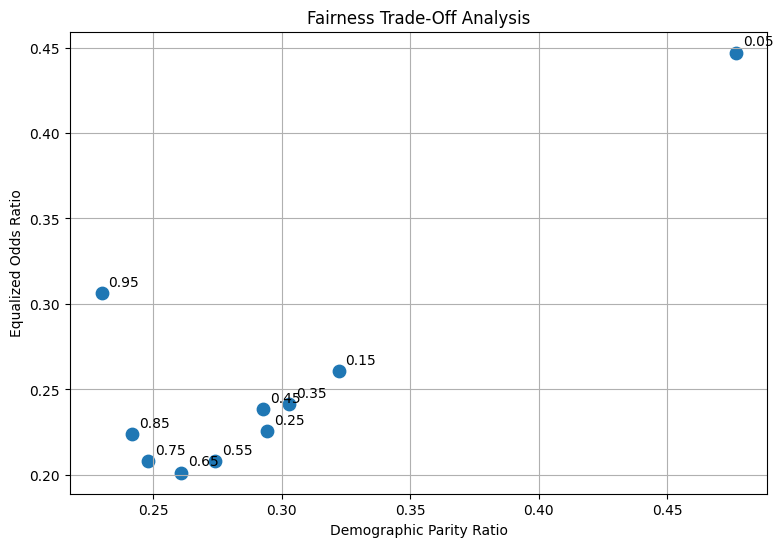

In [16]:

# Fairness Trade-Off Graph

plt.figure(figsize=(9, 6))

plt.scatter(
    fairness_df['DP'],
    fairness_df['EO'],
    s=80
)

for _, row in fairness_df.iterrows():
    plt.annotate(
        str(row['Threshold']),
        (row['DP'], row['EO']),
        xytext=(5, 5),
        textcoords='offset points'
    )

plt.xlabel("Demographic Parity Ratio")
plt.ylabel("Equalized Odds Ratio")
plt.title("Fairness Trade-Off Analysis")
plt.grid(True)

plt.show()


In [17]:

# Correct Fairness Metrics

fairness_results = []

for threshold in thresholds:

    predicted = (pred_b >= threshold).astype(int)

    metrics = {}

    for group, name in [(1, 'Male'), (0, 'Female')]:
        mask = gender == group

        yt = actual[mask]
        yp = predicted[mask]

        tn, fp, fn, tp = confusion_matrix(
            yt, yp, labels=[0, 1]
        ).ravel()

        metrics[name] = {
            'DP': np.mean(yp == 1),
            'TPR': tp / (tp + fn),
            'FPR': fp / (fp + tn),
            'PP': tp / (tp + fp) if (tp + fp) > 0 else np.nan
        }

    m = metrics['Male']
    f = metrics['Female']

    dp = m['DP'] / f['DP'] if f['DP'] > 0 else np.nan
    tpr = m['TPR'] / f['TPR'] if f['TPR'] > 0 else np.nan
    fpr = m['FPR'] / f['FPR'] if f['FPR'] > 0 else np.nan
    pp = m['PP'] / f['PP'] if f['PP'] > 0 else np.nan

    fairness_results.append({
        'Threshold': threshold,
        'DP': dp,
        'TPR Ratio': tpr,
        'FPR Ratio': fpr,
        'EO': min(tpr, fpr),
        'PP': pp
    })

fairness_df = pd.DataFrame(fairness_results)

print(fairness_df.round(4).to_string(index=False))


 Threshold     DP  TPR Ratio  FPR Ratio     EO     PP
      0.05 2.0979     1.0450     2.2374 1.0450 1.3959
      0.15 3.1046     1.1517     3.8370 1.1517 1.0395
      0.25 3.3968     1.1970     4.4347 1.1970 0.9875
      0.35 3.3013     1.1919     4.1454 1.1919 1.0117
      0.45 3.4172     1.2418     4.1926 1.2418 1.0183
      0.55 3.6491     1.2916     4.8087 1.2916 0.9918
      0.65 3.8353     1.3660     4.9682 1.3660 0.9980
      0.75 4.0342     1.4533     4.8034 1.4533 1.0095
      0.85 4.1355     1.4927     4.4639 1.4927 1.0115
      0.95 4.3502     1.5674     3.2663 1.5674 1.0096


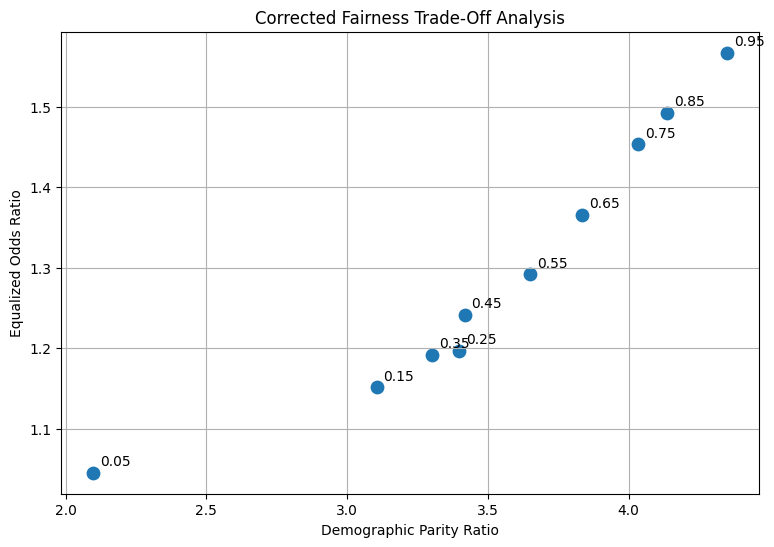

In [18]:

plt.figure(figsize=(9, 6))

plt.scatter(
    fairness_df['DP'],
    fairness_df['EO'],
    s=80
)

for _, row in fairness_df.iterrows():
    plt.annotate(
        str(round(row['Threshold'], 2)),
        (row['DP'], row['EO']),
        xytext=(5, 5),
        textcoords='offset points'
    )

plt.xlabel("Demographic Parity Ratio")
plt.ylabel("Equalized Odds Ratio")
plt.title("Corrected Fairness Trade-Off Analysis")
plt.grid(True)
plt.show()
